In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
import time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    f1_score, precision_score, recall_score
)

ROOT       = Path(r"D:\hocki7\Data Annalyst\Detai")
DATA_DIR   = ROOT / "1_data" / "processed"
MODEL_DIR  = ROOT / "4_models"
FIG_DIR    = ROOT / "5_reports" / "figures"

# Load tất cả tập dữ liệu đã chuẩn bị ở bước trước
X_train         = pd.read_csv(DATA_DIR / "X_train.csv")
X_val           = pd.read_csv(DATA_DIR / "X_val.csv")
X_test          = pd.read_csv(DATA_DIR / "X_test.csv")
y_train         = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_val           = pd.read_csv(DATA_DIR / "y_val.csv").squeeze()
y_test          = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

X_train_scaled  = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_val_scaled    = pd.read_csv(DATA_DIR / "X_val_scaled.csv")
X_test_scaled   = pd.read_csv(DATA_DIR / "X_test_scaled.csv")

X_train_smote   = pd.read_csv(DATA_DIR / "X_train_smote.csv")
y_train_smote   = pd.read_csv(DATA_DIR / "y_train_smote.csv").squeeze()

print("✅ Load xong toàn bộ dữ liệu:")
print(f"   Train       : {X_train.shape}")
print(f"   Validation  : {X_val.shape}")
print(f"   Test        : {X_test.shape}")
print(f"   Train SMOTE : {X_train_smote.shape}")

# Dictionary lưu kết quả tất cả mô hình để so sánh cuối cùng
results = {}

✅ Load xong toàn bộ dữ liệu:
   Train       : (139999, 47)
   Validation  : (30001, 47)
   Test        : (30000, 47)
   Train SMOTE : (251070, 47)


In [2]:
#Hàm đánh giá dùng chung cho mọi mô hình
def evaluate_model(model_name, y_true, y_pred, y_proba, results_dict, train_time=None):
    """
    Hàm đánh giá chuẩn hóa — dùng chung cho cả 3 mô hình
    để đảm bảo so sánh công bằng, cùng bộ metric
    """
    precision = precision_score(y_true, y_pred)
    recall    = recall_score(y_true, y_pred)
    f1        = f1_score(y_true, y_pred)
    roc_auc   = roc_auc_score(y_true, y_proba)

    # Precision-Recall AUC — quan trọng hơn ROC-AUC khi lớp mất cân bằng
    prec_curve, rec_curve, _ = precision_recall_curve(y_true, y_proba)
    pr_auc = auc(rec_curve, prec_curve)

    results_dict[model_name] = {
        'y_true'    : y_true,
        'y_pred'    : y_pred,
        'y_proba'   : y_proba,
        'precision' : precision,
        'recall'    : recall,
        'f1'        : f1,
        'roc_auc'   : roc_auc,
        'pr_auc'    : pr_auc,
        'train_time': train_time,
    }

    print(f"{'='*55}")
    print(f"  KẾT QUẢ: {model_name}")
    print(f"{'='*55}")
    print(f"  Precision : {precision:.4f}")
    print(f"  Recall    : {recall:.4f}")
    print(f"  F1-score  : {f1:.4f}")
    print(f"  ROC-AUC   : {roc_auc:.4f}")
    print(f"  PR-AUC    : {pr_auc:.4f}")
    if train_time:
        print(f"  Thời gian train: {train_time:.2f}s")

    print(f"\n  Confusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(f"              Dự đoán Không-fraud  Dự đoán Fraud")
    print(f"  Thực Không-fraud    {cm[0,0]:>10,}      {cm[0,1]:>10,}")
    print(f"  Thực Fraud          {cm[1,0]:>10,}      {cm[1,1]:>10,}")

print("✅ Hàm đánh giá đã sẵn sàng")

✅ Hàm đánh giá đã sẵn sàng


In [3]:
#MODEL 1: Logistic Regression
# ── Phiên bản A: class_weight='balanced' ────────────────────────
print("Training Logistic Regression — class_weight='balanced' ...")
t0 = time.time()

lr_balanced = LogisticRegression(
    class_weight='balanced',   # tự động tăng trọng số cho lớp fraud (lớp thiểu số)
    max_iter=1000,
    random_state=42
)
lr_balanced.fit(X_train_scaled, y_train)
train_time_a = time.time() - t0

y_pred_a  = lr_balanced.predict(X_test_scaled)
y_proba_a = lr_balanced.predict_proba(X_test_scaled)[:, 1]

evaluate_model('LogisticRegression_balanced', y_test, y_pred_a, y_proba_a,
                results, train_time_a)

# ── Phiên bản B: SMOTE ───────────────────────────────────────────
print("\nTraining Logistic Regression — SMOTE ...")
t0 = time.time()

lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
train_time_b = time.time() - t0

y_pred_b  = lr_smote.predict(X_test_scaled)
y_proba_b = lr_smote.predict_proba(X_test_scaled)[:, 1]

evaluate_model('LogisticRegression_smote', y_test, y_pred_b, y_proba_b,
                results, train_time_b)

Training Logistic Regression — class_weight='balanced' ...
  KẾT QUẢ: LogisticRegression_balanced
  Precision : 0.2248
  Recall    : 0.6967
  F1-score  : 0.3399
  ROC-AUC   : 0.7856
  PR-AUC    : 0.3300
  Thời gian train: 1.67s

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        19,456           7,445
  Thực Fraud                 940           2,159

Training Logistic Regression — SMOTE ...
  KẾT QUẢ: LogisticRegression_smote
  Precision : 0.2226
  Recall    : 0.6999
  F1-score  : 0.3377
  ROC-AUC   : 0.7854
  PR-AUC    : 0.3317
  Thời gian train: 3.08s

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        19,325           7,576
  Thực Fraud                 930           2,169


In [4]:
#MODEL 2: Random Forest
# ── Phiên bản A: class_weight='balanced' ────────────────────────
print("Training Random Forest — class_weight='balanced' ...")
t0 = time.time()

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1          # dùng toàn bộ CPU core để train nhanh hơn
)
rf_balanced.fit(X_train, y_train)      # Random Forest dùng data KHÔNG scale
train_time_a = time.time() - t0

y_pred_a  = rf_balanced.predict(X_test)
y_proba_a = rf_balanced.predict_proba(X_test)[:, 1]

evaluate_model('RandomForest_balanced', y_test, y_pred_a, y_proba_a,
                results, train_time_a)

# ── Phiên bản B: SMOTE ───────────────────────────────────────────
print("\nTraining Random Forest — SMOTE ...")
t0 = time.time()

# Lưu ý: X_train_smote hiện đang là bản ĐÃ SCALE (vì SMOTE áp dụng sau scale)
# Với Random Forest không bắt buộc, nhưng dùng tạm được vì cây không nhạy cảm scale
rf_smote = RandomForestClassifier(
    n_estimators=200, max_depth=15, random_state=42, n_jobs=-1
)
rf_smote.fit(X_train_smote, y_train_smote)
train_time_b = time.time() - t0

y_pred_b  = rf_smote.predict(X_test_scaled)
y_proba_b = rf_smote.predict_proba(X_test_scaled)[:, 1]

evaluate_model('RandomForest_smote', y_test, y_pred_b, y_proba_b,
                results, train_time_b)

# Lưu model tốt nhất để dùng sau (feature importance)
joblib.dump(rf_balanced, MODEL_DIR / "random_forest_balanced.pkl")

Training Random Forest — class_weight='balanced' ...
  KẾT QUẢ: RandomForest_balanced
  Precision : 0.5315
  Recall    : 0.6996
  F1-score  : 0.6041
  ROC-AUC   : 0.9132
  PR-AUC    : 0.6765
  Thời gian train: 29.36s

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        24,990           1,911
  Thực Fraud                 931           2,168

Training Random Forest — SMOTE ...
  KẾT QUẢ: RandomForest_smote
  Precision : 0.5041
  Recall    : 0.6621
  F1-score  : 0.5724
  ROC-AUC   : 0.8932
  PR-AUC    : 0.6348
  Thời gian train: 66.70s

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        24,882           2,019
  Thực Fraud               1,047           2,052


['D:\\hocki7\\Data Annalyst\\Detai\\4_models\\random_forest_balanced.pkl']

In [5]:
#Import TensorFlow, chuẩn bị dữ liệu
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
import random

# Cố định seed để kết quả tái hiện được
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Keras cần numpy float32, không dùng DataFrame
Xtr = X_train_scaled.values.astype('float32')
Xva = X_val_scaled.values.astype('float32')
Xte = X_test_scaled.values.astype('float32')
ytr = y_train.values.astype('float32')
yva = y_val.values.astype('float32')
yte = y_test.values.astype('float32')

# class_weight: lớp fraud (hiếm) bị phạt nặng hơn khi đoán sai
cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train.values)
class_weight = {0: cw[0], 1: cw[1]}

print(f"TensorFlow : {tf.__version__}")
print(f"Số đặc trưng đầu vào : {Xtr.shape[1]}")
print(f"class_weight         : {class_weight}")
print(f"→ Sai 1 ca fraud bị phạt nặng gấp {cw[1]/cw[0]:.1f} lần sai 1 ca bình thường")

TensorFlow : 2.21.0
Số đặc trưng đầu vào : 47
class_weight         : {0: np.float64(0.5576094316326125), 1: np.float64(4.839567201327434)}
→ Sai 1 ca fraud bị phạt nặng gấp 8.7 lần sai 1 ca bình thường


In [7]:
#Hàm dựng mạng và huấn luyện bản cơ bản
def build_mlp(n_features, units=(64, 32), dropout=0.3, lr=1e-3):
    """Xây MLP: [Dense -> Dropout] x N -> Output sigmoid"""
    model = keras.Sequential([layers.Input(shape=(n_features,))])
    for u in units:
        model.add(layers.Dense(u, activation='relu'))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='roc_auc'),
                 keras.metrics.AUC(curve='PR', name='pr_auc')]
    )
    return model

# Early Stopping: dừng khi PR-AUC trên VALIDATION không cải thiện nữa
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_pr_auc', mode='max',
    patience=8,                    # chờ 8 epoch không cải thiện thì dừng
    restore_best_weights=True      # quay về trọng số tốt nhất
)

model_base = build_mlp(Xtr.shape[1])
model_base.summary()

print("\nĐang train Neural Network cơ bản ...")
t0 = time.time()
history_base = model_base.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=100,
    batch_size=512,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=2
)
train_time_nn = time.time() - t0
print(f"\n✅ Train xong sau {len(history_base.history['loss'])} epoch | {train_time_nn:.1f}s")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,185 (20.25 KB)

 Trainable params: 5,185 (20.25 KB)

 Non-trainable params: 0 (0.00 B)


Đang train Neural Network cơ bản ...
Epoch 1/100
274/274 - 5s - 19ms/step - loss: 0.6041 - pr_auc: 0.2604 - roc_auc: 0.7397 - val_loss: 0.5569 - val_pr_auc: 0.3221 - val_roc_auc: 0.7926
Epoch 2/100
274/274 - 2s - 6ms/step - loss: 0.5628 - pr_auc: 0.3081 - roc_auc: 0.7841 - val_loss: 0.5482 - val_pr_auc: 0.3380 - val_roc_auc: 0.8036
Epoch 3/100
274/274 - 2s - 6ms/step - loss: 0.5533 - pr_auc: 0.3238 - roc_auc: 0.7933 - val_loss: 0.5388 - val_pr_auc: 0.3517 - val_roc_auc: 0.8091
Epoch 4/100
274/274 - 2s - 6ms/step - loss: 0.5454 - pr_auc: 0.3367 - roc_auc: 0.8009 - val_loss: 0.5322 - val_pr_auc: 0.3655 - val_roc_auc: 0.8148
Epoch 5/100
274/274 - 1s - 5ms/step - loss: 0.5400 - pr_auc: 0.3434 - roc_auc: 0.8060 - val_loss: 0.5252 - val_pr_auc: 0.3749 - val_roc_auc: 0.8181
Epoch 6/100
274/274 - 2s - 7ms/step - loss: 0.5354 - pr_auc: 0.3525 - roc_auc: 0.8096 - val_loss: 0.5089 - val_pr_auc: 0.3854 - val_roc_auc: 0.8219
Epoch 7/100
274/274 - 2s - 6ms/step - loss: 0.5322 - pr_auc: 0.3612 - roc

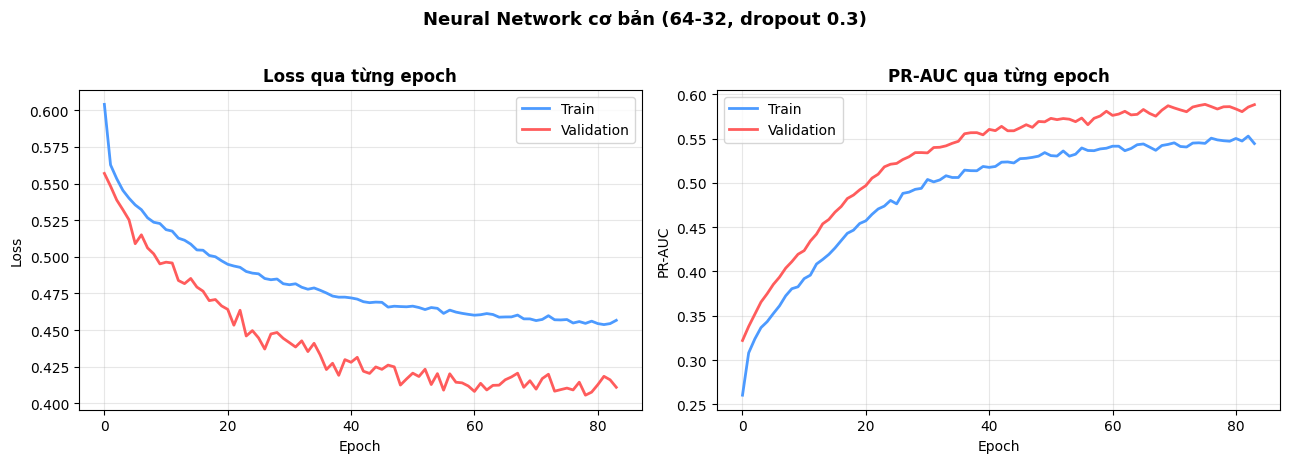

Epoch tốt nhất: 76 | val PR-AUC = 0.5886


In [8]:
#Biểu đồ learning curve (train vs validation)
def plot_history(history, title, save_name):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(h['loss'], label='Train', color='#4C9AFF', linewidth=2)
    axes[0].plot(h['val_loss'], label='Validation', color='#FF5C5C', linewidth=2)
    axes[0].set_title('Loss qua từng epoch', fontweight='bold')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(h['pr_auc'], label='Train', color='#4C9AFF', linewidth=2)
    axes[1].plot(h['val_pr_auc'], label='Validation', color='#FF5C5C', linewidth=2)
    axes[1].set_title('PR-AUC qua từng epoch', fontweight='bold')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('PR-AUC')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(str(FIG_DIR / save_name), dpi=150, bbox_inches='tight')
    plt.show()

plot_history(history_base, 'Neural Network cơ bản (64-32, dropout 0.3)', '07_nn_base_history.png')

best_ep = int(np.argmax(history_base.history['val_pr_auc'])) + 1
print(f"Epoch tốt nhất: {best_ep} | val PR-AUC = {max(history_base.history['val_pr_auc']):.4f}")

In [9]:
#Đánh giá trên tập Test (ngưỡng 0.5)

proba_nn = model_base.predict(Xte, batch_size=2048, verbose=0).ravel()
pred_nn  = (proba_nn >= 0.5).astype(int)

evaluate_model('NN_baseline', y_test, pred_nn, proba_nn, results, train_time_nn)

  KẾT QUẢ: NN_baseline
  Precision : 0.3365
  Recall    : 0.7315
  F1-score  : 0.4610
  ROC-AUC   : 0.8707
  PR-AUC    : 0.5904
  Thời gian train: 175.24s

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        22,432           4,469
  Thực Fraud                 832           2,267


In [22]:
#cell 9
#Tối ưu ngưỡng quyết định trên Validation (áp dụng công bằng cho cả RF)
def best_threshold_on_val(y_val_true, y_val_proba):
    """Chọn ngưỡng cho F1 cao nhất trên tập VALIDATION"""
    prec, rec, thr = precision_recall_curve(y_val_true, y_val_proba)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    i = np.argmax(f1s)
    return thr[i], f1s[i]

# --- Neural Network ---
proba_val_nn = model_base.predict(Xva, batch_size=2048, verbose=0).ravel()
thr_nn, f1_val_nn = best_threshold_on_val(yva, proba_val_nn)
print(f"NN  : ngưỡng tốt nhất trên val = {thr_nn:.3f} (F1 val = {f1_val_nn:.4f})")
evaluate_model('NN_baseline_thr', y_test, (proba_nn >= thr_nn).astype(int), proba_nn, results)

# --- Random Forest (để so sánh công bằng) ---
proba_val_rf = rf_balanced.predict_proba(X_val)[:, 1]
thr_rf, f1_val_rf = best_threshold_on_val(y_val.values, proba_val_rf)
proba_test_rf = rf_balanced.predict_proba(X_test)[:, 1]
print(f"\nRF  : ngưỡng tốt nhất trên val = {thr_rf:.3f} (F1 val = {f1_val_rf:.4f})")
evaluate_model('RF_balanced_thr', y_test, (proba_test_rf >= thr_rf).astype(int), proba_test_rf, results)

NN  : ngưỡng tốt nhất trên val = 0.697 (F1 val = 0.5429)
  KẾT QUẢ: NN_baseline_thr
  Precision : 0.5627
  Recall    : 0.5186
  F1-score  : 0.5397
  ROC-AUC   : 0.8707
  PR-AUC    : 0.5904

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        25,652           1,249
  Thực Fraud               1,492           1,607

RF  : ngưỡng tốt nhất trên val = 0.577 (F1 val = 0.6239)
  KẾT QUẢ: RF_balanced_thr
  Precision : 0.6250
  Recall    : 0.6044
  F1-score  : 0.6145
  ROC-AUC   : 0.9132
  PR-AUC    : 0.6765

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        25,777           1,124
  Thực Fraud               1,226           1,873


In [ ]:
#Tối ưu mạng neuron

In [ ]:
#Cell 10 : Log transform cho các cột lệch
from sklearn.preprocessing import StandardScaler
import gc

SKEW = [c for c in ['dist1', 'dist2', 'D10', 'D_total', 'C_total'] if c in X_train.columns]

def slog(df):
    """Log có dấu: giữ được giá trị âm (D_total có thể âm)"""
    d = df.copy()
    for c in SKEW:
        d[c] = np.sign(d[c]) * np.log1p(d[c].abs())
    return d

Xtr_l, Xva_l, Xte_l = slog(X_train), slog(X_val), slog(X_test)
sc_l = StandardScaler().fit(Xtr_l)          # fit chỉ trên train

datasets = {
    'std': (Xtr, Xva, Xte),                 # bản cũ: chỉ StandardScaler
    'log': tuple(sc_l.transform(d).astype('float32') for d in (Xtr_l, Xva_l, Xte_l)),
}

print("Độ lệch (skewness) trước và sau log, gần 0 là cân đối:")
print(pd.DataFrame({'trước': X_train[SKEW].skew().round(1),
                    'sau'  : Xtr_l[SKEW].skew().round(1)}))

Độ lệch (skewness) trước và sau log, gần 0 là cân đối:
         trước  sau
dist1      8.8  2.1
dist2     23.8 -0.7
D10        1.7  0.2
D_total    1.6 -0.4
C_total   21.3  2.8


In [18]:
#khung thí nghiệm
FAST = dict(units=(128, 64), dropout=0.3, activation='relu', batchnorm=False,
            l2=0.0, optimizer='adam', lr=3e-3, batch_size=2048)
fast_log, fast_hist, fast_models = [], {}, {}

def run_fast(name, data_key, **changes):
    cfg = {**FAST, **changes}
    Xt, Xv, _ = datasets[data_key]
    keras.utils.set_random_seed(SEED)
    model = build_mlp_v2(Xt.shape[1], cfg['units'], cfg['dropout'], cfg['activation'],
                         cfg['batchnorm'], cfg['l2'], cfg['optimizer'], cfg['lr'])
    cbs = [
        keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max',
                                      patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc', mode='max',
                                          factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    h = model.fit(Xt, ytr, validation_data=(Xv, yva), epochs=60,
                  batch_size=cfg['batch_size'], class_weight=class_weight,
                  callbacks=cbs, verbose=0)
    dt = time.time() - t0

    curve = h.history['val_pr_auc']
    rec = dict(name=name, data=data_key, val_pr_auc=max(curve),
               best_epoch=int(np.argmax(curve)) + 1, epochs_run=len(curve),
               time_s=round(dt), params=model.count_params(),
               units=str(cfg['units']), dropout=cfg['dropout'],
               batchnorm=cfg['batchnorm'], l2=cfg['l2'])
    fast_log.append(rec); fast_hist[name] = h.history; fast_models[name] = model
    print(f"{name:<18} [{data_key}] val PR-AUC={rec['val_pr_auc']:.4f} | "
          f"best_ep={rec['best_epoch']:>2}/{rec['epochs_run']:>2} | {dt:>4.0f}s")

def show_fast():
    df = pd.DataFrame(fast_log).sort_values('val_pr_auc', ascending=False)
    print(df[['name', 'data', 'units', 'dropout', 'val_pr_auc', 'best_epoch', 'time_s']]
          .to_string(index=False))

print("✅ Sẵn sàng")

✅ Sẵn sàng


In [14]:
#Vòng 1, kiểm tra tốc độ và log transform
run_fast('F0_std_128-64', 'std')
run_fast('F1_log_128-64', 'log')
print()
show_fast()

F0_std_128-64      [std] val PR-AUC=0.6160 | best_ep=60/60 |   59s
F1_log_128-64      [log] val PR-AUC=0.6450 | best_ep=59/60 |   83s

         name data     units  dropout  val_pr_auc  best_epoch  time_s
F1_log_128-64  log (128, 64)      0.3     0.64495          59      83
F0_std_128-64  std (128, 64)      0.3     0.61599          60      59


In [15]:
#Vòng 2, kiến trúc và dropout
DK = 'log'      # Kết quả vòng 1 chứng minh 'log' vượt trội

run_fast('G1_256-128',          DK, units=(256, 128))
run_fast('G2_128-64_drop0.15',  DK, dropout=0.15)
run_fast('G3_256-128_drop0.15', DK, units=(256, 128), dropout=0.15)
print()
show_fast()

G1_256-128         [log] val PR-AUC=0.6809 | best_ep=60/60 |   95s
G2_128-64_drop0.15 [log] val PR-AUC=0.6633 | best_ep=58/60 |   64s
G3_256-128_drop0.15 [log] val PR-AUC=0.6952 | best_ep=60/60 |  103s

               name data      units  dropout  val_pr_auc  best_epoch  time_s
G3_256-128_drop0.15  log (256, 128)     0.15    0.695183          60     103
         G1_256-128  log (256, 128)     0.30    0.680935          60      95
 G2_128-64_drop0.15  log  (128, 64)     0.15    0.663278          58      64
      F1_log_128-64  log  (128, 64)     0.30    0.644950          59      83
      F0_std_128-64  std  (128, 64)     0.30    0.615990          60      59


In [19]:
#Vòng 3, tùy chọn (BatchNorm và L2)
DK = 'log'
UNITS, DROP = (256, 128), 0.15    # Cập nhật chính xác theo cấu hình thắng G3

run_fast('H1_batchnorm', DK, units=UNITS, dropout=DROP, batchnorm=True)
run_fast('H2_l2_1e-4',   DK, units=UNITS, dropout=DROP, l2=1e-4)
print()
show_fast()

# Lưu log để dùng làm bảng trong báo cáo
pd.DataFrame(fast_log).to_csv(ROOT / "1_data" / "exports" / "nn_experiments.csv", index=False)

H1_batchnorm       [log] val PR-AUC=0.6808 | best_ep=60/60 |  157s
H2_l2_1e-4         [log] val PR-AUC=0.6823 | best_ep=60/60 |  102s

        name data      units  dropout  val_pr_auc  best_epoch  time_s
  H2_l2_1e-4  log (256, 128)     0.15    0.682288          60     102
H1_batchnorm  log (256, 128)     0.15    0.680761          60     157


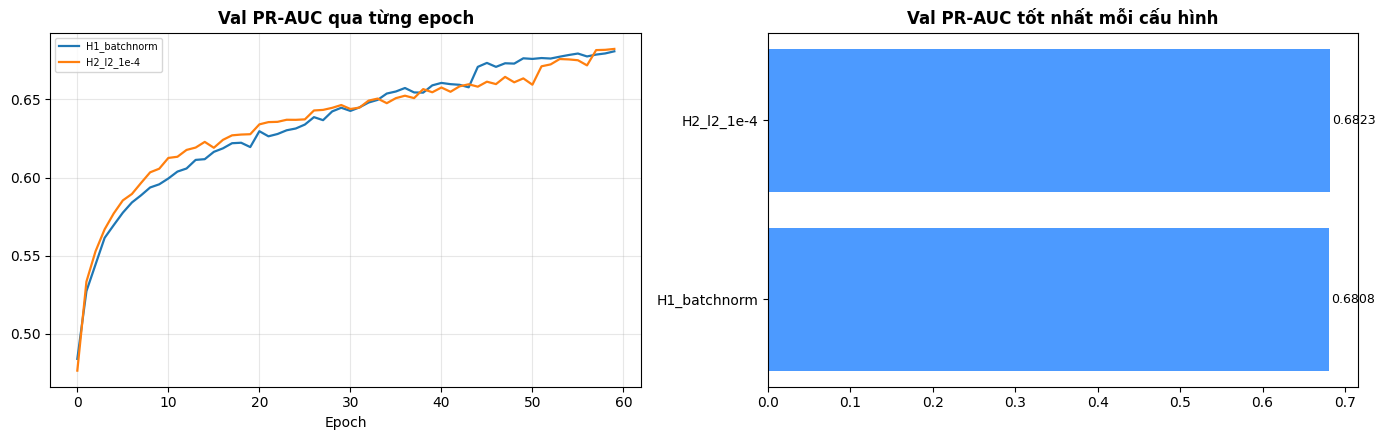

In [20]:
#Biểu đồ so sánh các cấu hình
df_f = pd.DataFrame(fast_log).sort_values('val_pr_auc')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

for n, h in fast_hist.items():
    ax[0].plot(h['val_pr_auc'], label=n, linewidth=1.6)
ax[0].set_title('Val PR-AUC qua từng epoch', fontweight='bold')
ax[0].set_xlabel('Epoch'); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)

ax[1].barh(df_f['name'], df_f['val_pr_auc'], color='#4C9AFF')
for i, v in enumerate(df_f['val_pr_auc']):
    ax[1].text(v + 0.002, i, f"{v:.4f}", va='center', fontsize=9)
ax[1].set_title('Val PR-AUC tốt nhất mỗi cấu hình', fontweight='bold')
plt.tight_layout()
plt.savefig(str(FIG_DIR / "08_nn_tuning.png"), dpi=150, bbox_inches='tight')
plt.show()

In [23]:
#Chấm điểm cuối trên tập Test
best = max(fast_log, key=lambda r: r['val_pr_auc'])
print(f"Cấu hình thắng: {best['name']} | data={best['data']} | "
      f"units={best['units']} | dropout={best['dropout']} | val PR-AUC={best['val_pr_auc']:.4f}")

model_best = fast_models[best['name']]
_, Xv_b, Xt_b = datasets[best['data']]

proba_val  = model_best.predict(Xv_b, batch_size=4096, verbose=0).ravel()
proba_test = model_best.predict(Xt_b, batch_size=4096, verbose=0).ravel()

thr, f1_val = best_threshold_on_val(yva, proba_val)
print(f"Ngưỡng chọn trên validation: {thr:.3f} (F1 val = {f1_val:.4f})\n")

evaluate_model('NN_optimized_thr', y_test, (proba_test >= thr).astype(int), proba_test, results)

model_best.save(MODEL_DIR / "nn_optimized.keras")
print("\n✅ Đã lưu model: 4_models/nn_optimized.keras")

Cấu hình thắng: H2_l2_1e-4 | data=log | units=(256, 128) | dropout=0.15 | val PR-AUC=0.6823
Ngưỡng chọn trên validation: 0.743 (F1 val = 0.6231)

  KẾT QUẢ: NN_optimized_thr
  Precision : 0.6156
  Recall    : 0.6299
  F1-score  : 0.6226
  ROC-AUC   : 0.9056
  PR-AUC    : 0.6767

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        25,682           1,219
  Thực Fraud               1,147           1,952

✅ Đã lưu model: 4_models/nn_optimized.keras


In [24]:
#Train lâu hơn và thêm đặc trưng tần suất
# Thêm đặc trưng tần suất (chỉ đếm trên TRAIN)
FREQ = ['card1', 'addr1']

def add_freq(dtr, dva, dte, cols):
    out = [d.copy() for d in (dtr, dva, dte)]
    for c in cols:
        vc = dtr[c].value_counts()                      # đếm trên train
        for d in out:
            d[c + '_freq'] = np.log1p(d[c].map(vc).fillna(0))
    return out

Xtr_f, Xva_f, Xte_f = add_freq(Xtr_l, Xva_l, Xte_l, FREQ)
sc_f = StandardScaler().fit(Xtr_f)
datasets['log_freq'] = tuple(sc_f.transform(d).astype('float32')
                             for d in (Xtr_f, Xva_f, Xte_f))
print(f"Số đặc trưng: {datasets['log'][0].shape[1]} -> {datasets['log_freq'][0].shape[1]}")

# Bản run_fast có tham số epochs
def run_fast(name, data_key, epochs=60, patience=8, **changes):
    cfg = {**FAST, **changes}
    Xt, Xv, _ = datasets[data_key]
    keras.utils.set_random_seed(SEED)
    model = build_mlp_v2(Xt.shape[1], cfg['units'], cfg['dropout'], cfg['activation'],
                         cfg['batchnorm'], cfg['l2'], cfg['optimizer'], cfg['lr'])
    cbs = [
        keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max',
                                      patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc', mode='max',
                                          factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    h = model.fit(Xt, ytr, validation_data=(Xv, yva), epochs=epochs,
                  batch_size=cfg['batch_size'], class_weight=class_weight,
                  callbacks=cbs, verbose=0)
    dt = time.time() - t0
    curve = h.history['val_pr_auc']
    rec = dict(name=name, data=data_key, val_pr_auc=max(curve),
               best_epoch=int(np.argmax(curve)) + 1, epochs_run=len(curve),
               time_s=round(dt), params=model.count_params(),
               units=str(cfg['units']), dropout=cfg['dropout'],
               batchnorm=cfg['batchnorm'], l2=cfg['l2'])
    fast_log.append(rec); fast_hist[name] = h.history; fast_models[name] = model
    print(f"{name:<18} [{data_key}] val PR-AUC={rec['val_pr_auc']:.4f} | "
          f"best_ep={rec['best_epoch']:>3}/{rec['epochs_run']:>3} | {dt:>4.0f}s")

# Cấu hình thắng ở vòng trước: (256,128), dropout 0.15, l2 1e-4
CFG = dict(units=(256, 128), dropout=0.15, l2=1e-4)

run_fast('J1_log_120ep',      'log',      epochs=120, patience=10, **CFG)
run_fast('J2_logfreq_120ep',  'log_freq', epochs=120, patience=10, **CFG)
print()
show_fast()

Số đặc trưng: 47 -> 49
J1_log_120ep       [log] val PR-AUC=0.6902 | best_ep= 77/ 87 |  164s
J2_logfreq_120ep   [log_freq] val PR-AUC=0.7245 | best_ep= 92/102 |  162s

            name     data      units  dropout  val_pr_auc  best_epoch  time_s
J2_logfreq_120ep log_freq (256, 128)     0.15    0.724536          92     162
    J1_log_120ep      log (256, 128)     0.15    0.690209          77     164
      H2_l2_1e-4      log (256, 128)     0.15    0.682288          60     102
    H1_batchnorm      log (256, 128)     0.15    0.680761          60     157


In [25]:
#Ghép NN với RF, chấm điểm cuối trên Test
from sklearn.metrics import average_precision_score

best = max(fast_log, key=lambda r: r['val_pr_auc'])
print(f"NN tốt nhất: {best['name']} | data={best['data']} | val PR-AUC={best['val_pr_auc']:.4f}")

model_b = fast_models[best['name']]
_, Xv_b, Xt_b = datasets[best['data']]
pv_nn = model_b.predict(Xv_b, batch_size=4096, verbose=0).ravel()
pt_nn = model_b.predict(Xt_b, batch_size=4096, verbose=0).ravel()

# 1) NN đơn lẻ (ngưỡng chọn trên val)
thr, _ = best_threshold_on_val(yva, pv_nn)
evaluate_model('NN_final_thr', y_test, (pt_nn >= thr).astype(int), pt_nn, results)

# 2) Ghép NN + RF: chọn trọng số w trên VALIDATION
ws = np.linspace(0, 1, 11)
scores = [average_precision_score(yva, w * pv_nn + (1 - w) * proba_val_rf) for w in ws]
w_best = ws[int(np.argmax(scores))]
print(f"\nTrọng số NN tốt nhất trên val: w={w_best:.1f} (RF = {1 - w_best:.1f}) | "
      f"val PR-AUC={max(scores):.4f}")

pv_ens = w_best * pv_nn + (1 - w_best) * proba_val_rf
pt_ens = w_best * pt_nn + (1 - w_best) * proba_test_rf
thr_e, _ = best_threshold_on_val(yva, pv_ens)
evaluate_model('Ensemble_NN_RF_thr', y_test, (pt_ens >= thr_e).astype(int), pt_ens, results)

model_b.save(MODEL_DIR / "nn_final.keras")

NN tốt nhất: J2_logfreq_120ep | data=log_freq | val PR-AUC=0.7245
  KẾT QUẢ: NN_final_thr
  Precision : 0.6632
  Recall    : 0.6499
  F1-score  : 0.6565
  ROC-AUC   : 0.9191
  PR-AUC    : 0.7160

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        25,878           1,023
  Thực Fraud               1,085           2,014

Trọng số NN tốt nhất trên val: w=0.7 (RF = 0.3) | val PR-AUC=0.7383
  KẾT QUẢ: Ensemble_NN_RF_thr
  Precision : 0.6944
  Recall    : 0.6402
  F1-score  : 0.6662
  ROC-AUC   : 0.9244
  PR-AUC    : 0.7302

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        26,028             873
  Thực Fraud               1,115           1,984


In [26]:
#RF công bằng, cùng đặc trưng với NN
# Cùng đặc trưng với NN (log + freq), nhưng không cần scale
t0 = time.time()
rf_fair = RandomForestClassifier(
    n_estimators=200, max_depth=15, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf_fair.fit(Xtr_f, y_train)
t_rf = time.time() - t0

pv_rf2 = rf_fair.predict_proba(Xva_f)[:, 1]
pt_rf2 = rf_fair.predict_proba(Xte_f)[:, 1]
thr_rf2, _ = best_threshold_on_val(y_val.values, pv_rf2)
evaluate_model('RF_fair_thr', y_test, (pt_rf2 >= thr_rf2).astype(int), pt_rf2, results, t_rf)

joblib.dump(rf_fair, MODEL_DIR / "random_forest_fair.pkl")

  KẾT QUẢ: RF_fair_thr
  Precision : 0.6668
  Recall    : 0.6257
  F1-score  : 0.6456
  ROC-AUC   : 0.9245
  PR-AUC    : 0.7101
  Thời gian train: 26.63s

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        25,932             969
  Thực Fraud               1,160           1,939


['D:\\hocki7\\Data Annalyst\\Detai\\4_models\\random_forest_fair.pkl']

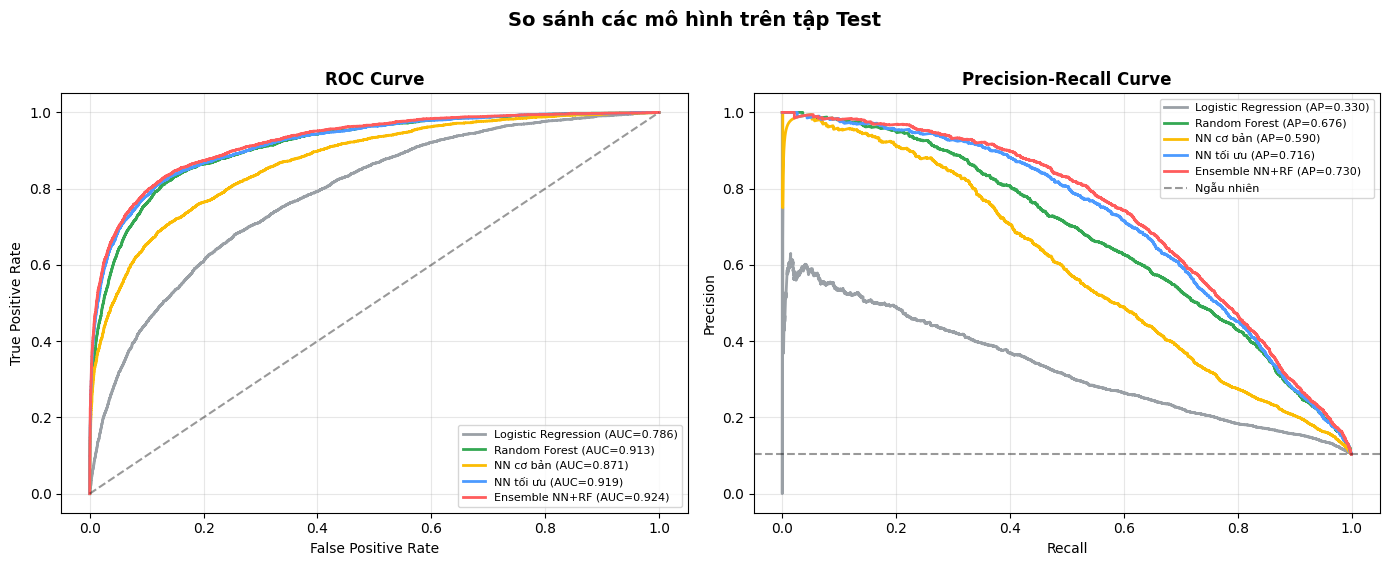

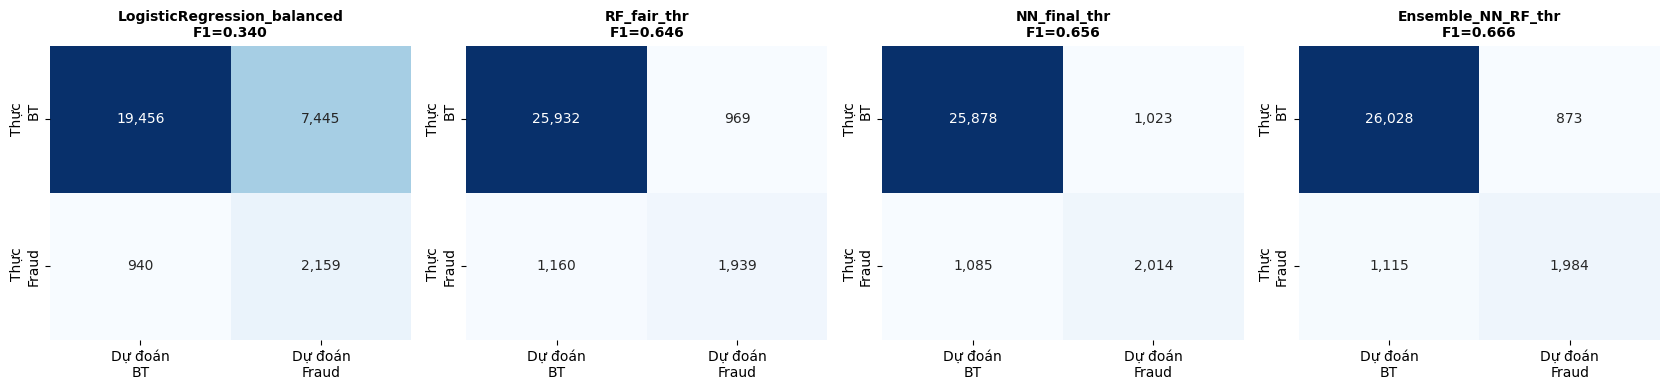

                             precision  recall      f1  roc_auc  pr_auc
Ensemble_NN_RF_thr              0.6944  0.6402  0.6662   0.9244  0.7302
NN_final_thr                    0.6632  0.6499  0.6565   0.9191  0.7160
RF_fair_thr                     0.6668  0.6257  0.6456   0.9245  0.7101
NN_optimized_thr                0.6156  0.6299  0.6226   0.9056  0.6767
RF_balanced_thr                 0.6250  0.6044  0.6145   0.9132  0.6765
RandomForest_balanced           0.5315  0.6996  0.6041   0.9132  0.6765
RandomForest_smote              0.5041  0.6621  0.5724   0.8932  0.6348
NN_baseline_thr                 0.5627  0.5186  0.5397   0.8707  0.5904
NN_baseline                     0.3365  0.7315  0.4610   0.8707  0.5904
LogisticRegression_smote        0.2226  0.6999  0.3377   0.7854  0.3317
LogisticRegression_balanced     0.2248  0.6967  0.3399   0.7856  0.3300


In [27]:
#ROC, PR curve và Confusion Matrix cho cả các mô hình
MODELS = {   # tên trong results -> nhãn hiển thị, màu
    'LogisticRegression_balanced': ('Logistic Regression', '#9AA0A6'),
    'RandomForest_balanced'      : ('Random Forest',       '#34A853'),
    'NN_baseline'                : ('NN cơ bản',           '#FBBC04'),
    'NN_final_thr'               : ('NN tối ưu',           '#4C9AFF'),
    'Ensemble_NN_RF_thr'         : ('Ensemble NN+RF',      '#FF5C5C'),
}
MODELS = {k: v for k, v in MODELS.items() if k in results}

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k, (label, color) in MODELS.items():
    r = results[k]
    fpr, tpr, _ = roc_curve(r['y_true'], r['y_proba'])
    ax[0].plot(fpr, tpr, color=color, linewidth=2, label=f"{label} (AUC={r['roc_auc']:.3f})")
    p, rc, _ = precision_recall_curve(r['y_true'], r['y_proba'])
    ax[1].plot(rc, p, color=color, linewidth=2, label=f"{label} (AP={r['pr_auc']:.3f})")

ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax[0].set_title('ROC Curve', fontweight='bold')
ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate')
ax[1].axhline(y_test.mean(), color='k', linestyle='--', alpha=0.4, label='Ngẫu nhiên')
ax[1].set_title('Precision-Recall Curve', fontweight='bold')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.suptitle('So sánh các mô hình trên tập Test', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / "12_roc_pr_comparison.png"), dpi=150, bbox_inches='tight')
plt.show()

# Confusion matrix: các mô hình dùng ngưỡng tối ưu
cm_keys = [k for k in ['LogisticRegression_balanced', 'RF_fair_thr', 'NN_final_thr',
                       'Ensemble_NN_RF_thr'] if k in results]
fig, axes = plt.subplots(1, len(cm_keys), figsize=(4.2 * len(cm_keys), 4))
for a, k in zip(np.atleast_1d(axes), cm_keys):
    r = results[k]
    cm = confusion_matrix(r['y_true'], r['y_pred'])
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Dự đoán\nBT', 'Dự đoán\nFraud'],
                yticklabels=['Thực\nBT', 'Thực\nFraud'])
    a.set_title(f"{k}\nF1={r['f1']:.3f}", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(str(FIG_DIR / "13_confusion_matrices.png"), dpi=150, bbox_inches='tight')
plt.show()

# Bảng tổng hợp để đưa vào báo cáo
summary = pd.DataFrame({k: {m: results[k][m] for m in
                            ['precision', 'recall', 'f1', 'roc_auc', 'pr_auc']}
                        for k in results}).T.round(4).sort_values('pr_auc', ascending=False)
print(summary.to_string())
summary.to_csv(ROOT / "1_data" / "exports" / "model_comparison.csv")

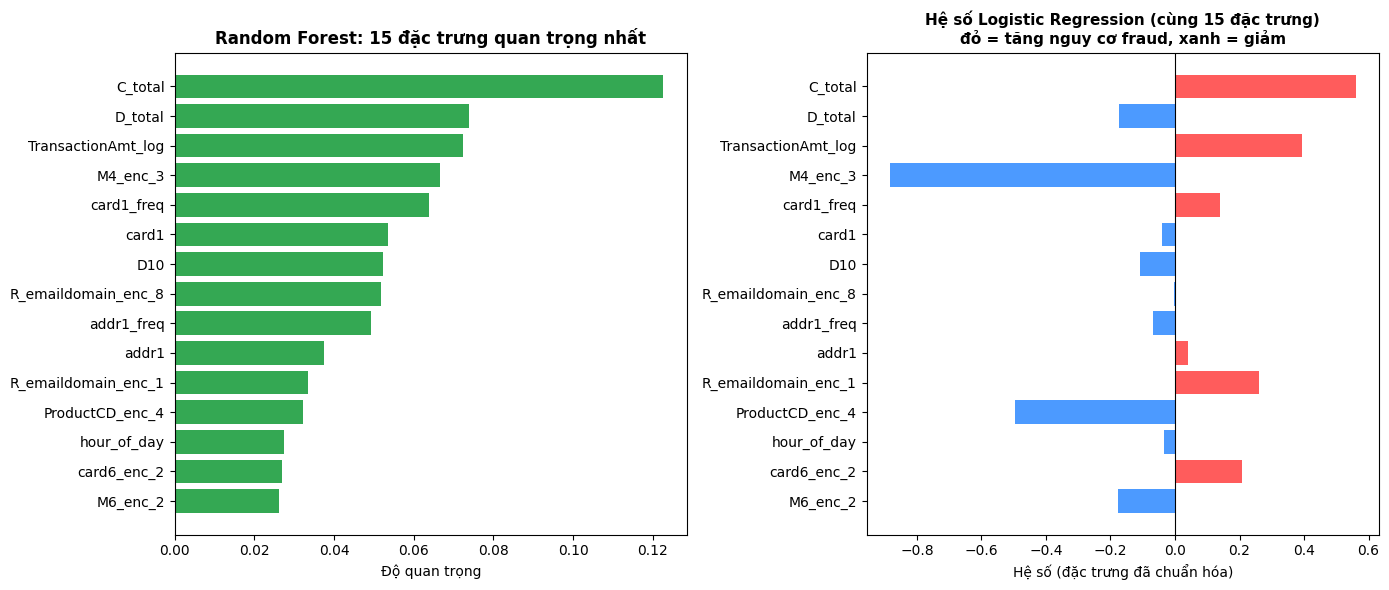

Top 10 đặc trưng RF:
C_total                0.1225
D_total                0.0740
TransactionAmt_log     0.0725
M4_enc_3               0.0665
card1_freq             0.0638
card1                  0.0536
D10                    0.0522
R_emaildomain_enc_8    0.0517
addr1_freq             0.0493
addr1                  0.0375


In [28]:
#Feature importance của RF đối chiếu hệ số LR
cols = list(Xtr_f.columns)

# RF: độ quan trọng (mean decrease in impurity)
imp_rf = pd.Series(rf_fair.feature_importances_, index=cols).sort_values(ascending=False)

# LR: huấn luyện trên cùng đặc trưng log+freq (đã scale) để hệ số so sánh được
lr_fair = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
lr_fair.fit(datasets['log_freq'][0], y_train)
coef_lr = pd.Series(lr_fair.coef_[0], index=cols)

top = imp_rf.head(15)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].barh(top.index[::-1], top.values[::-1], color='#34A853')
ax[0].set_title('Random Forest: 15 đặc trưng quan trọng nhất', fontweight='bold')
ax[0].set_xlabel('Độ quan trọng')

c = coef_lr.reindex(top.index)
ax[1].barh(c.index[::-1], c.values[::-1],
           color=['#FF5C5C' if v > 0 else '#4C9AFF' for v in c.values[::-1]])
ax[1].axvline(0, color='k', linewidth=0.8)
ax[1].set_title('Hệ số Logistic Regression (cùng 15 đặc trưng)\nđỏ = tăng nguy cơ fraud, xanh = giảm',
                fontweight='bold', fontsize=11)
ax[1].set_xlabel('Hệ số (đặc trưng đã chuẩn hóa)')

plt.tight_layout()
plt.savefig(str(FIG_DIR / "14_feature_importance.png"), dpi=150, bbox_inches='tight')
plt.show()

print("Top 10 đặc trưng RF:")
print(imp_rf.head(10).round(4).to_string())

In [29]:
#Kiểm chứng giả thuyết, bỏ đặc trưng tần suất rồi so sánh (ablation)
# Cùng cấu hình RF, chỉ khác có/không có 2 cột tần suất
freq_cols = ['card1_freq', 'addr1_freq']
keep = [c for c in cols if c not in freq_cols]

rf_noF = RandomForestClassifier(n_estimators=200, max_depth=15,
                                class_weight='balanced', random_state=42, n_jobs=-1)
rf_noF.fit(Xtr_f[keep], y_train)

pv = rf_noF.predict_proba(Xva_f[keep])[:, 1]
pt = rf_noF.predict_proba(Xte_f[keep])[:, 1]
thr_n, _ = best_threshold_on_val(y_val.values, pv)
evaluate_model('RF_no_freq_thr', y_test, (pt >= thr_n).astype(int), pt, results)

print("\nSo sánh (test):")
print(f"  RF không có freq : PR-AUC = {results['RF_no_freq_thr']['pr_auc']:.4f}")
print(f"  RF có freq       : PR-AUC = {results['RF_fair_thr']['pr_auc']:.4f}")

  KẾT QUẢ: RF_no_freq_thr
  Precision : 0.6253
  Recall    : 0.6047
  F1-score  : 0.6148
  ROC-AUC   : 0.9133
  PR-AUC    : 0.6767

  Confusion Matrix:
              Dự đoán Không-fraud  Dự đoán Fraud
  Thực Không-fraud        25,778           1,123
  Thực Fraud               1,225           1,874

So sánh (test):
  RF không có freq : PR-AUC = 0.6767
  RF có freq       : PR-AUC = 0.7101


Fraud thật: 3,099 | bắt được: 1,984 | bỏ sót: 1,115

                    Bắt được (median)  Bỏ sót (median)
TransactionAmt_log               4.22             4.44
hour_of_day                     16.00            16.00
D10                              0.00             1.00
C_total                         10.00             4.00
dist1                            8.00             8.00


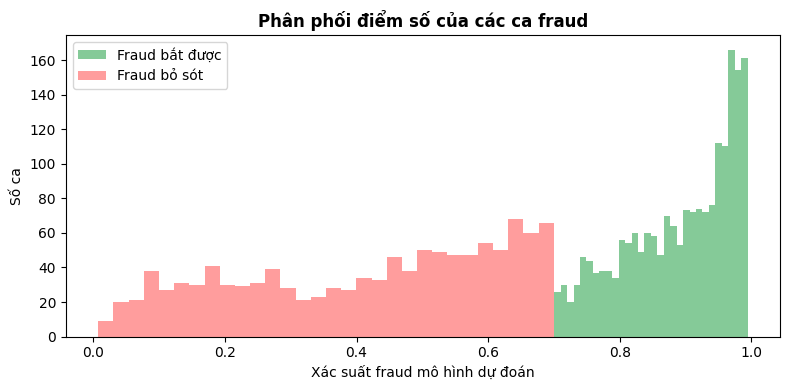

In [30]:
#Phân tích lỗi, ca fraud nào bị bỏ sót
r = results['Ensemble_NN_RF_thr']
te = X_test.reset_index(drop=True).copy()
te['y'] = np.asarray(r['y_true']); te['pred'] = np.asarray(r['y_pred'])
te['proba'] = np.asarray(r['y_proba'])

fraud = te[te['y'] == 1]
caught, missed = fraud[fraud['pred'] == 1], fraud[fraud['pred'] == 0]
print(f"Fraud thật: {len(fraud):,} | bắt được: {len(caught):,} | bỏ sót: {len(missed):,}\n")

compare_cols = [c for c in ['TransactionAmt_log', 'hour_of_day', 'D10', 'C_total', 'dist1']
                if c in te.columns]
print(pd.DataFrame({'Bắt được (median)': caught[compare_cols].median(),
                    'Bỏ sót (median)'  : missed[compare_cols].median()}).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(caught['proba'], bins=30, alpha=0.6, label='Fraud bắt được', color='#34A853')
ax.hist(missed['proba'], bins=30, alpha=0.6, label='Fraud bỏ sót', color='#FF5C5C')
ax.set_xlabel('Xác suất fraud mô hình dự đoán'); ax.set_ylabel('Số ca')
ax.set_title('Phân phối điểm số của các ca fraud', fontweight='bold'); ax.legend()
plt.tight_layout()
plt.savefig(str(FIG_DIR / "15_error_analysis.png"), dpi=150, bbox_inches='tight')
plt.show()